In [144]:
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline


In [ ]:
dataset = pd.read_csv("final.csv")
dataset

,country,year,nkill,nwound,value,inequality,deaths_civilians,nkilldelay1,nkilldelay2,nwounddelay1,nwounddelay2
0,afghanistan,1995,0.0,0.0,0.329,0.269101,185.0,25.0,1.0,169.0,3.0
1,afghanistan,2001,153.0,5.0,0.355,0.309670,915.0,0.0,25.0,0.0,169.0
2,afghanistan,2002,47.0,190.0,0.383,0.276151,171.0,153.0,0.0,5.0,0.0
3,afghanistan,2003,112.0,169.0,0.392,0.276151,67.0,47.0,153.0,190.0,5.0
4,afghanistan,2004,195.0,129.0,0.408,0.276151,77.0,112.0,47.0,169.0,190.0
...,...,...,...,...,...,...,...,...,...,...,...
850,yemen,2015,1648.0,2183.0,0.475,0.625497,2298.0,1161.0,457.0,1071.0,590.0
851,yemen,2016,1291.0,1147.0,0.467,0.644826,883.0,1648.0,1161.0,2183.0,1071.0
852,yemen,2017,679.0,608.0,0.459,0.644826,855.0,1291.0,1648.0,1147.0,2183.0
853,zambia,2000,0.0,2.0,0.429,0.241663,1.0,1.0,20.0,1.0,22.0


In [146]:
features = ["deaths_civilians", "nkilldelay1", "nkilldelay2", "nwounddelay1", "nwounddelay2"]
targets = ["nkill", "nwound"]
log_dataset = dataset.copy()

for col in features + targets:
    log_dataset[col] = np.log1p(log_dataset[col])
features = features + ["year"]
targets = targets + ["year"]
X = log_dataset[features].drop(["nwounddelay1", "nwounddelay2"], axis=1)
y = log_dataset[targets].drop("nwound", axis=1)
X_train = X[X["year"] <= 2014].drop("year", axis=1)
y_train = y[y["year"] <= 2014].drop("year", axis=1)
X_test = X[X["year"] > 2014].drop("year", axis=1)
y_test = y[y["year"] > 2014].drop("year", axis=1)





In [147]:

lr = make_pipeline(StandardScaler(), LinearRegression())
lr.fit(X_train, y_train)
regularized = make_pipeline(StandardScaler(), Ridge())
regularized.fit(X_train, y_train)


,steps,"[('standardscaler', ...), ('ridge', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None


In [148]:
lr.score(X_test, y_test)


0.7333085537231441

In [149]:
regularized.score(X_test, y_test)

0.7332837741496594

In [150]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

In [151]:
y_pred = lr.predict(X_test)
regularized_pred = regularized.predict(X_test)

In [152]:
mean_absolute_error(np.expm1(y_test), np.expm1(y_pred))

224.11911626326597

In [153]:
mean_absolute_error(np.expm1(y_test), np.expm1(regularized_pred))

224.61123263801625

In [154]:
median_absolute_error(np.expm1(y_test), np.expm1(y_pred))

18.507131834793782

In [155]:
median_absolute_error(np.expm1(y_test), np.expm1(regularized_pred))

18.620961959169918

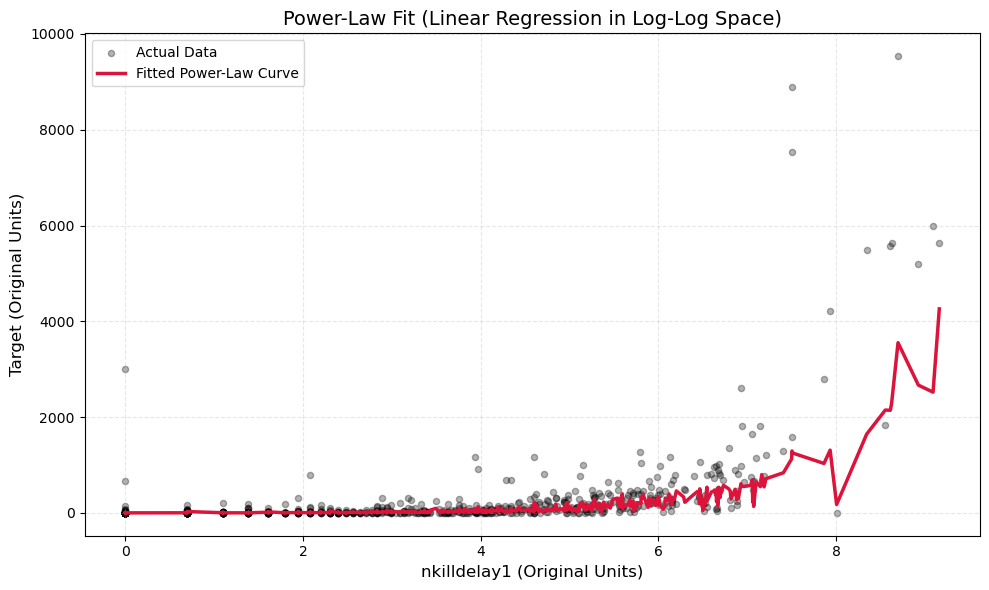

In [156]:

X = X.drop("year", axis=1)
y_pred_original = np.expm1(regularized.predict(X))
y_actual_original = np.expm1(y.drop("year", axis=1))


# Choose a primary feature to visualize (e.g., your first lag in original units)
feature_name = "nkilldelay1"
x_original_feature = X[feature_name] # values before log transform


# Sort by the feature values so the line plots as a clean, continuous curve
sorted_idx = np.argsort(x_original_feature)

plt.figure(figsize=(10, 6))

# 1. The scatter plot of your actual power-law distributed data
plt.scatter(
    x_original_feature, 
    y_actual_original, 
    color='black', 
    alpha=0.3, 
    s=20, 
    label='Actual Data'
)

# 2. The fitted power-law curve from your model
plt.plot(
    x_original_feature.iloc[sorted_idx], 
    y_pred_original[sorted_idx], 
    color='crimson', 
    linewidth=2.5, 
    label='Fitted Power-Law Curve'
)

plt.xlabel(f'{feature_name} (Original Units)', fontsize=12)
plt.ylabel('Target (Original Units)', fontsize=12)
plt.title('Power-Law Fit (Linear Regression in Log-Log Space)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()


In [157]:
import joblib
joblib.dump(lr, "linear_regression_model.pkl")

['linear_regression_model.pkl']

In [158]:
X_test

,deaths_civilians,nkilldelay1,nkilldelay2
15,6.809039,8.345218,7.933797
16,6.991177,8.611230,8.345218
17,6.974479,8.626048,8.611230
40,0.693147,3.218876,2.484907
41,0.000000,2.833213,3.218876
...,...,...,...
834,5.637790,3.784190,2.833213
835,5.637790,3.988984,3.784190
850,7.740230,7.057898,6.126869
851,6.784457,7.407924,7.057898


In [159]:
loaded_model = joblib.load("linear_regression_model.pkl")
np.expm1(loaded_model.predict(X_test))

array([[1.65000406e+03],
       [2.14999543e+03],
       [2.29475895e+03],
       [9.46707026e+00],
       [7.87125929e+00],
       [9.75008482e-01],
       [3.30855959e+01],
       [6.14509061e+00],
       [4.72823927e+00],
       [5.42718978e+00],
       [2.30345488e+00],
       [2.89015153e-01],
       [2.89015153e-01],
       [6.59374389e-01],
       [8.51546307e+00],
       [2.68954789e+01],
       [2.86894868e+01],
       [4.50985829e+00],
       [1.72127297e+01],
       [1.61244803e+01],
       [3.65731400e+00],
       [1.51438291e+02],
       [4.58342618e+02],
       [2.39709784e+02],
       [1.90589491e+00],
       [6.60778693e-01],
       [4.55098417e-01],
       [2.48686336e+02],
       [1.85257336e+02],
       [8.31622314e+01],
       [2.23701512e+01],
       [3.94582975e+01],
       [2.33774862e+01],
       [1.02215452e+00],
       [6.78127519e-01],
       [3.01590075e+01],
       [5.04809984e+01],
       [1.04815090e+01],
       [7.94928682e+01],
       [7.01764188e+01],
